# Bajo peso al nacer en Colombia, 2005-2024

Equivale a los do-files de `Code/stata` (`01_Base_y_Resultados_Generales.do` y `02_Indice_Concentracion.do`).

- **Datos:** microdatos de nacimientos de las Estadísticas Vitales del DANE, leídos y armonizados con `dane-data` (`dd.eevv`). Si falta algún año: `dd.eevv.download(range(2005, 2025), tipos="nacimientos")`.
- **Resultados:** los Excel y los gráficos se guardan en `3.0 Datos/python`.
- La primera corrida tarda cerca de un minuto; después `dane-data` lee su caché.

In [1]:
from pathlib import Path

import dane_data as dd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from dane_data.referencias import DEPARTAMENTOS
from scipy.stats import norm

# Jupyter corre la notebook desde su carpeta (Code/python). Sin parents=True: si la carpeta no es esa, falla aquí.
RESULTADOS = Path.cwd().parents[1] / "3.0 Datos" / "python"
RESULTADOS.mkdir(exist_ok=True)

ANIOS_GEN = range(2005, 2025)  # resultados generales
ANIOS_IC = range(2008, 2025)   # índice de concentración: el régimen de salud es comparable desde 2008
TRIENIOS = {"2008-2010": range(2008, 2011), "2022-2024": range(2022, 2025)}
BOGOTA = 11
CODIGOS = {nombre: cod for cod, nombre in DEPARTAMENTOS.items()}
SIN_DPTO = "Sin información / exterior"
AZUL, NARANJA, ROJO = "#08306B", "#A63603", "#C00000"
FUENTE = "Fuente: DANE, Estadísticas Vitales. Cálculos propios."
ORDENAMIENTO = ("Ordenamiento: % de madres en régimen subsidiado (más subsidiado = más pobre). "
                "Ponderación: nacidos vivos.")

## Parte 1. Resultados generales por año, 2005-2024

Nacional, por departamento de residencia de la madre, por sexo del nacido vivo y distribución del peso al nacer.

`bajo_peso` de `dane-data` es `True` si `PESO_NAC` es 1-4 (menos de 2.500 g), `False` si es 5-8 y vacío si es 9 (sin información). El % de bajo peso se calcula sobre los nacidos vivos con peso conocido.

In [2]:
# Nacidos vivos (n) por año y grupo; dropna=False cuenta también los que no tienen el dato
conteos = dd.eevv.serie_conteos(ANIOS_GEN, tipo="nacimientos",
                                por=["departamento_residencia", "sexo", "peso_grupo", "bajo_peso"], dropna=False)
conteos["con_peso"] = conteos.n * conteos.bajo_peso.notna()
conteos["bpn_n"] = conteos.n * conteos.bajo_peso.fillna(False).astype(bool)

ETQ_GEN = {
    "anio": "Año",
    "dpto_res": "Código departamento",
    "departamento": "Departamento",
    "nacidos_vivos": "Nacidos vivos",
    "con_peso": "Nacidos vivos con peso conocido",
    "sin_info_peso": "Sin información de peso",
    "bpn_n": "Nacidos con bajo peso (<2.500 g)",
    "pct_bpn": "% bajo peso al nacer",
    "archivo": "Archivo leído",
    "registros": "Registros",
}


def resumen(por):
    """Nacidos vivos, con peso conocido y con bajo peso, y el % de bajo peso, por grupo."""
    r = (conteos.groupby(por, observed=True, dropna=False)[["n", "con_peso", "bpn_n"]].sum()
         .reset_index().rename(columns={"n": "nacidos_vivos"}))
    r["pct_bpn"] = 100 * r.bpn_n / r.con_peso
    return r

### B1. Nacional por año

In [3]:
nac = resumen(["anio"])
nac.insert(3, "sin_info_peso", nac.nacidos_vivos - nac.con_peso)
nac.round(2)

,anio,nacidos_vivos,con_peso,sin_info_peso,bpn_n,pct_bpn
0,2005,719968,704310,15658,58362,8.29
1,2006,714450,702965,11485,60296,8.58
2,2007,709253,701122,8131,60971,8.70
3,2008,715453,708577,6876,62719,8.85
4,2009,699775,694913,4862,63088,9.08
5,2010,654627,651305,3322,59180,9.09
6,2011,665499,662408,3091,59960,9.05
7,2012,676835,673201,3634,60472,8.98
8,2013,658835,655090,3745,58784,8.97
9,2014,669137,666229,2908,58326,8.75


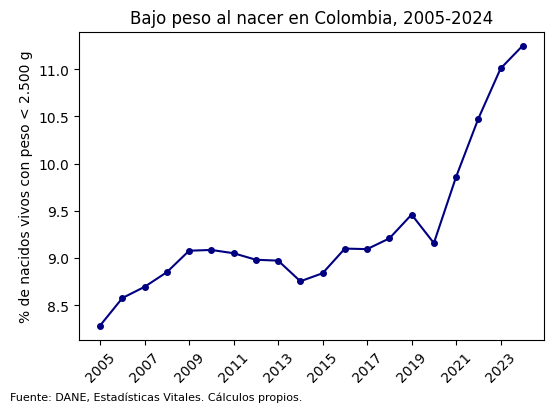

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(nac.anio, nac.pct_bpn, "o-", color="navy", ms=4)
ax.set(ylabel="% de nacidos vivos con peso < 2.500 g", xticks=ANIOS_GEN[::2],
       title=f"Bajo peso al nacer en Colombia, {ANIOS_GEN[0]}-{ANIOS_GEN[-1]}")
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter("{x:.1f}")
fig.text(0.01, -0.02, FUENTE, fontsize=8, va="top")
fig.savefig(RESULTADOS / "G1_bpn_nacional.png", dpi=300, bbox_inches="tight")

### B2. Por departamento de residencia de la madre y año

Código 0: madre sin información de departamento o residente en el exterior.

In [5]:
dep = resumen(["departamento_residencia", "anio"])
dep["departamento"] = dep.pop("departamento_residencia").astype(object).fillna(SIN_DPTO)
dep.insert(0, "dpto_res", dep.departamento.map(CODIGOS).fillna(0).astype(int))
dep = dep.sort_values(["dpto_res", "anio"])[["dpto_res", "departamento", "anio", "nacidos_vivos", "con_peso",
                                             "bpn_n", "pct_bpn"]]
# % de bajo peso en formato ancho: departamentos en filas y años en columnas
dep_ancho = dep.pivot(index=["dpto_res", "departamento"], columns="anio", values="pct_bpn").reset_index()
dep_ancho.round(2)

anio,dpto_res,departamento,2005,2006,2007,2008,2009,2010,2011,2012,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,0,Sin información / exterior,13.74,14.14,13.37,8.57,8.18,8.64,12.17,14.58,...,17.94,18.67,12.60,10.60,9.87,8.75,9.51,10.60,11.33,13.00
1,5,Antioquia,9.09,9.33,9.12,9.45,9.59,9.63,9.41,9.13,...,9.23,9.33,9.59,9.54,9.53,9.20,10.33,10.72,11.26,11.32
2,8,Atlántico,7.35,8.23,8.35,8.36,8.66,8.60,9.03,8.60,...,8.83,9.01,8.50,8.74,9.22,8.69,9.35,10.12,11.40,10.70
3,11,Bogotá D.C.,12.01,12.23,12.43,12.41,12.85,12.95,13.29,12.94,...,12.15,12.59,13.15,13.48,13.95,13.53,14.90,15.23,16.08,16.51
4,13,Bolívar,7.39,7.26,7.84,7.57,7.52,7.72,7.95,8.15,...,7.75,8.51,8.10,7.83,8.18,8.49,8.59,9.56,10.04,9.95
5,15,Boyacá,8.57,8.62,8.84,9.25,9.36,9.55,9.26,9.52,...,9.30,9.57,9.61,10.17,9.96,10.01,10.39,11.52,11.60,11.69
6,17,Caldas,6.52,6.89,6.56,6.65,6.82,6.84,6.73,7.50,...,7.90,8.29,8.36,7.85,9.41,9.01,10.12,10.21,11.81,11.97
7,18,Caquetá,5.06,5.97,5.17,5.79,6.12,5.97,6.57,6.30,...,5.94,5.58,6.39,5.90,5.73,5.81,5.22,6.10,6.29,5.67
8,19,Cauca,8.01,8.15,8.31,7.95,8.82,8.20,8.06,8.07,...,8.41,8.06,8.29,8.40,8.35,8.10,8.36,9.53,9.69,9.98
9,20,Cesar,6.89,7.04,7.67,8.50,8.52,7.84,7.86,8.79,...,8.13,8.15,8.28,7.84,8.46,8.26,8.02,9.10,9.08,9.34


### B3. Por sexo del nacido vivo y año

In [6]:
sx = resumen(["anio", "sexo"])
sx = sx[sx.sexo.isin(["Hombre", "Mujer"])].assign(sexo=lambda d: d.sexo.astype(str))
sx = sx.pivot(index="anio", columns="sexo", values=["nacidos_vivos", "bpn_n", "pct_bpn"])
nombres = {"nacidos_vivos": "Nacidos vivos", "bpn_n": "Bajo peso", "pct_bpn": "% BPN"}
plural = {"Hombre": "Hombres", "Mujer": "Mujeres"}
columnas_sexo = [(v, s) for s in plural for v in nombres]
sx = sx[columnas_sexo].set_axis([f"{nombres[v]} - {plural[s]}" for v, s in columnas_sexo], axis=1).reset_index()
sx.round(2)

,anio,Nacidos vivos - Hombres,Bajo peso - Hombres,% BPN - Hombres,Nacidos vivos - Mujeres,Bajo peso - Mujeres,% BPN - Mujeres
0,2005,370628.0,27730.0,7.65,349340.0,30632.0,8.96
1,2006,366728.0,28342.0,7.85,347722.0,31954.0,9.34
2,2007,364352.0,28795.0,7.99,344901.0,32176.0,9.44
3,2008,369752.0,29754.0,8.13,345701.0,32965.0,9.63
4,2009,360578.0,29894.0,8.35,339197.0,33194.0,9.86
5,2010,337025.0,27793.0,8.29,317602.0,31387.0,9.93
6,2011,341406.0,28199.0,8.30,324093.0,31761.0,9.85
7,2012,347070.0,28548.0,8.27,329765.0,31924.0,9.73
8,2013,337947.0,27804.0,8.27,320888.0,30980.0,9.71
9,2014,343163.0,27628.0,8.09,325968.0,30698.0,9.46


### B4. Distribución del peso al nacer por año (%)

Sobre los nacidos vivos con peso conocido.

In [7]:
pg = conteos[conteos.peso_grupo.notna() & conteos.peso_grupo.ne("Sin información")]
dist = pg.groupby(["anio", "peso_grupo"], observed=True).n.sum()
dist = (100 * dist / dist.groupby(level="anio").transform("sum")).unstack().dropna(axis=1, how="all").reset_index()
dist.round(2)

peso_grupo,anio,Menos de 1.000,1.000 a 1.499,1.500 a 1.999,2.000 a 2.499,2.500 a 2.999,3.000 a 3.499,3.500 a 3.999,4.000 y más
0,2005,0.33,0.67,1.49,5.80,24.54,41.60,21.03,4.54
1,2006,0.36,0.68,1.53,6.01,24.90,41.67,20.56,4.29
2,2007,0.38,0.69,1.55,6.07,25.14,41.75,20.25,4.16
3,2008,0.38,0.72,1.61,6.15,25.40,41.82,19.99,3.94
4,2009,0.37,0.71,1.66,6.33,26.13,41.89,19.25,3.65
5,2010,0.39,0.73,1.61,6.36,26.41,41.99,19.02,3.49
6,2011,0.41,0.74,1.65,6.25,26.16,42.19,19.06,3.54
7,2012,0.39,0.72,1.65,6.22,26.46,42.46,18.78,3.32
8,2013,0.41,0.74,1.70,6.13,26.80,42.43,18.66,3.14
9,2014,0.39,0.72,1.64,6.00,26.69,42.67,18.71,3.17


### Control: archivo del DANE leído cada año

In [8]:
ctl = dd.eevv.available().query("tipo == 'nacimientos' and @ANIOS_GEN[0] <= anio <= @ANIOS_GEN[-1]")
ctl = ctl[["anio", "archivo"]].merge(nac[["anio", "nacidos_vivos"]].rename(columns={"nacidos_vivos": "registros"}),
                                     on="anio")
ctl

,anio,archivo,registros
0,2005,Nacimientos_2005.txt,719968
1,2006,Nacimientos_2006.txt,714450
2,2007,Nacimientos_2007.txt,709253
3,2008,nac2008.csv,715453
4,2009,nac2009.csv,699775
5,2010,nac2010.csv,654627
6,2011,nac2011.csv,665499
7,2012,Nac_2012.txt,676835
8,2013,Nac_2013.txt,658835
9,2014,nac2014.csv,669137


In [9]:
with pd.ExcelWriter(RESULTADOS / "Resultados_generales_por_anio.xlsx") as xl:
    for hoja, df in {"Nacional": nac, "Departamento_largo": dep, "Departamento_%BPN": dep_ancho, "Sexo": sx,
                     "Distribucion_peso": dist, "Control_carga": ctl}.items():
        df.rename(columns=ETQ_GEN).to_excel(xl, sheet_name=hoja, index=False)

## Parte 2. Desigualdad socioeconómica del bajo peso al nacer entre departamentos, 2008-2024

- **Indicador socioeconómico:** % de madres en régimen subsidiado del departamento y año (más subsidiado = más pobre).
- **Ponderación:** nacidos vivos con peso conocido del departamento (no se usan proyecciones de población).
- **Sensibilidad:** (i) pobre = subsidiado + no asegurado; (ii) sin Bogotá, cuyo bajo peso alto se asocia a la altitud y no a la pobreza.

El índice de concentración se calcula con la regresión conveniente (O'Donnell et al., 2008, cap. 8) sobre datos agrupados, una fila por departamento:

$$2\,\sigma_r^2\,\frac{h_i}{\mu} = \alpha + C\,r_i + \varepsilon_i$$

$h_i$ es el % de bajo peso del departamento, $\mu$ su media ponderada, $r_i$ el rango fraccional ponderado según el indicador socioeconómico (de menor a mayor condición) y $C$ el índice, con error estándar robusto (HC1, igual al `vce(robust)` de Stata). El índice de Erreygers (2009) para una variable acotada entre 0 y 100 es $E = 4\mu C/100$.

In [10]:
def ic_conc(d, h, w, rango):
    """
    Índice de concentración con datos agrupados (una fila = un departamento).
      h = prevalencia de BPN (%), w = ponderación, rango = indicador de MENOR a MAYOR condición.
    """
    d = d.sort_values(rango, kind="stable")
    W = d[w].sum()
    r = (d[w].cumsum() - d[w] / 2) / W
    mu = np.average(d[h], weights=d[w])
    var_r = (d[w] * (r - 0.5) ** 2).sum() / W
    lhs = 2 * var_r * d[h] / mu
    m = sm.WLS(lhs, sm.add_constant(r), weights=d[w]).fit(cov_type="HC1")
    C, se = m.params.iloc[1], m.bse.iloc[1]
    # La pendiente debe ser la fórmula de covarianza del IC: 2·cov_w(h, r) / mu
    assert np.isclose(C, 2 * np.average((d[h] - mu) * (r - 0.5), weights=d[w]) / mu)
    return {"ndptos": int(m.nobs), "mu": mu, "C": C, "seC": se, "E": 4 * mu / 100 * C, "seE": 4 * mu / 100 * se}


def indices(d):
    """IC principal, sensibilidad con subsidiado + no asegurado, y sin Bogotá."""
    d = d[(d.con_peso > 0) & d.pct_sub.notna()]
    res = ic_conc(d, "pct_bpn", "con_peso", "ses")
    res["C_sens"] = ic_conc(d, "pct_bpn", "con_peso", "ses_na")["C"]
    res["C_sinbog"] = ic_conc(d[d.dpto_res != BOGOTA], "pct_bpn", "con_peso", "ses")["C"]
    return res


SUMAS = ["nacidos", "con_peso", "bpn_n", "reg_conocido", "n_sub", "n_sub_na"]


def agregar(d, por):
    """Suma los conteos por grupo y calcula los porcentajes."""
    r = d.groupby(por, observed=True)[SUMAS].sum().reset_index()
    r["pct_bpn"] = 100 * r.bpn_n / r.con_peso
    r["pct_sub"] = 100 * r.n_sub / r.reg_conocido
    r["pct_sub_na"] = 100 * r.n_sub_na / r.reg_conocido
    r["ses"] = 100 - r.pct_sub        # principal: % NO subsidiado (mayor = mejor condición)
    r["ses_na"] = 100 - r.pct_sub_na  # sensibilidad: % ni subsidiado ni no asegurado
    return r


def coma(x):
    return f"{x:.3f}".replace(".", ",")


ETQ_IC = {
    "anio": "Año", "dpto_res": "Código departamento", "departamento": "Departamento", "nacidos": "Nacidos vivos",
    "con_peso": "Nacidos vivos con peso conocido (ponderación)", "bpn_n": "Nacidos con bajo peso (<2.500 g)",
    "pct_bpn": "% bajo peso al nacer", "reg_conocido": "Nacidos con régimen conocido",
    "n_sub": "Madres en régimen subsidiado", "pct_sub": "% madres en régimen subsidiado",
    "pct_sub_na": "% madres subsidiado o no aseguradas", "ndptos": "Departamentos", "mu": "% BPN (media ponderada)",
    "C": "Índice de concentración", "seC": "Error estándar IC", "li_C": "IC 95 % inferior",
    "ls_C": "IC 95 % superior", "p_C": "Valor p (IC = 0)", "E": "Índice de Erreygers",
    "seE": "Error estándar Erreygers", "C_sens": "IC sensibilidad (subsidiado + no asegurado)",
    "C_sinbog": "IC sensibilidad (sin Bogotá)", "periodo": "Periodo", "orden": "Orden (1 = más subsidiado)",
}

### A. Panel departamento-año

Quedan fuera las madres residentes en el exterior o sin departamento. Régimen (códigos del DANE desde 2008): contributivo, excepción y especial juntos; subsidiado; no asegurado. «Sin información» y los códigos fuera del diccionario no cuentan como régimen conocido.

In [11]:
conteos_ic = dd.eevv.serie_conteos(ANIOS_IC, tipo="nacimientos",
                                   por=["departamento_residencia", "regimen_salud", "bajo_peso"], dropna=False)
conteos_ic = conteos_ic[conteos_ic.departamento_residencia.notna()]

reg = conteos_ic.regimen_salud.astype(object)
n = conteos_ic.n
conteos_ic = conteos_ic.assign(
    departamento=conteos_ic.departamento_residencia.astype(object),
    nacidos=n,
    con_peso=n * conteos_ic.bajo_peso.notna(),
    bpn_n=n * conteos_ic.bajo_peso.fillna(False).astype(bool),
    reg_conocido=n * reg.isin(["Contributivo", "Excepción", "Especial", "Subsidiado", "No asegurado"]),
    n_sub=n * reg.eq("Subsidiado"),
    n_sub_na=n * reg.isin(["Subsidiado", "No asegurado"]),
)
# Revisión: distribución del régimen por año (%)
pd.crosstab(conteos_ic.anio, reg, values=n, aggfunc="sum", normalize="index", dropna=False).mul(100).round(1)

regimen_salud,Contributivo,Especial,Excepción,No asegurado,Sin información,Subsidiado
anio,,,,,,
2008,37.6,0.3,1.8,12.8,2.1,45.4
2009,37.4,0.2,2.1,11.5,1.3,47.4
2010,38.4,0.2,2.4,10.9,0.7,47.3
2011,38.9,0.3,2.5,8.2,0.2,49.9
2012,39.1,0.0,2.7,6.1,0.2,52.0
2013,39.4,0.0,2.6,4.7,0.1,53.1
2014,40.5,0.0,2.6,3.4,0.1,53.5
2015,43.1,0.0,2.6,2.6,0.0,51.6
2016,43.4,0.0,2.5,2.3,0.0,51.7


In [12]:
panel = agregar(conteos_ic, ["anio", "departamento"])
panel.insert(1, "dpto_res", panel.departamento.map(CODIGOS))
panel = panel.sort_values(["anio", "dpto_res"], ignore_index=True)
panel.round(2)

,anio,dpto_res,departamento,nacidos,con_peso,bpn_n,reg_conocido,n_sub,n_sub_na,pct_bpn,pct_sub,pct_sub_na,ses,ses_na
0,2008,5,Antioquia,90973,90291,8529,89297,41197,50843,9.45,46.13,56.94,53.87,43.06
1,2008,8,Atlántico,41432,41268,3448,40080,18858,21835,8.36,47.05,54.48,52.95,45.52
2,2008,11,Bogotá D.C.,117590,117473,14584,116836,23875,41704,12.41,20.43,35.69,79.57,64.31
3,2008,13,Bolívar,30851,30744,2327,29683,18839,21727,7.57,63.47,73.20,36.53,26.80
4,2008,15,Boyacá,19193,19098,1766,19109,12311,12886,9.25,64.43,67.43,35.57,32.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
556,2024,91,Amazonas,773,671,63,772,593,615,9.39,76.81,79.66,23.19,20.34
557,2024,94,Guainía,714,691,55,713,571,647,7.96,80.08,90.74,19.92,9.26
558,2024,95,Guaviare,992,985,77,992,741,770,7.82,74.70,77.62,25.30,22.38
559,2024,97,Vaupés,545,403,27,545,482,492,6.70,88.44,90.28,11.56,9.72


### B. Índice de concentración por año

In [13]:
ic = pd.DataFrame([{"anio": a, **indices(g)} for a, g in panel.groupby("anio")])
ic["li_C"] = ic.C - 1.96 * ic.seC
ic["ls_C"] = ic.C + 1.96 * ic.seC
ic["p_C"] = 2 * norm.sf(abs(ic.C / ic.seC))
ic = ic[["anio", "ndptos", "mu", "C", "seC", "li_C", "ls_C", "p_C", "E", "seE", "C_sens", "C_sinbog"]]
ic.round(4)

,anio,ndptos,mu,C,seC,li_C,ls_C,p_C,E,seE,C_sens,C_sinbog
0,2008,33,8.8521,0.0839,0.0311,0.0230,0.1447,0.0069,0.0297,0.0110,0.0880,0.0265
1,2009,33,9.0811,0.0831,0.0327,0.0189,0.1472,0.0112,0.0302,0.0119,0.0871,0.0215
2,2010,33,9.0873,0.0951,0.0307,0.0349,0.1553,0.0020,0.0346,0.0112,0.0930,0.0359
3,2011,33,9.0488,0.0949,0.0352,0.0259,0.1639,0.0070,0.0344,0.0127,0.0985,0.0298
4,2012,33,8.9791,0.0856,0.0339,0.0191,0.1521,0.0116,0.0307,0.0122,0.0886,0.0253
5,2013,33,8.9703,0.0833,0.0341,0.0164,0.1502,0.0146,0.0299,0.0122,0.0901,0.0235
6,2014,33,8.7496,0.0748,0.0317,0.0127,0.1370,0.0182,0.0262,0.0111,0.0781,0.0193
7,2015,33,8.8366,0.0730,0.0294,0.0153,0.1306,0.0131,0.0258,0.0104,0.0733,0.0217
8,2016,33,9.0950,0.0766,0.0282,0.0213,0.1319,0.0067,0.0279,0.0103,0.0767,0.0272
9,2017,33,9.0886,0.0851,0.0313,0.0237,0.1464,0.0066,0.0309,0.0114,0.0829,0.0323


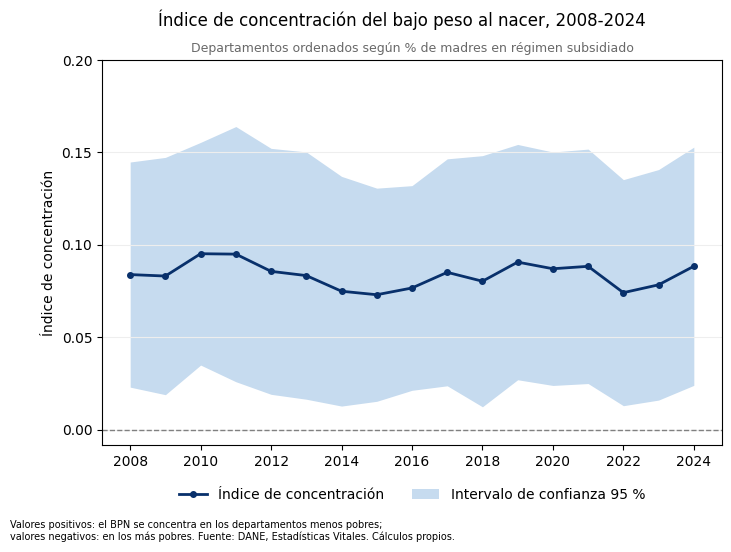

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(ic.anio, ic.li_C, ic.ls_C, color="#C6DBEF", lw=0, label="Intervalo de confianza 95 %")
ax.plot(ic.anio, ic.C, "o-", color=AZUL, lw=2, ms=4, label="Índice de concentración")
ax.axhline(0, color="grey", ls="--", lw=1)
ax.set_yticks(np.arange(0, 0.21, 0.05))
ax.yaxis.set_major_formatter("{x:.2f}")
ax.set_xticks(ANIOS_IC[::2])
ax.grid(axis="y", color="#EEEEEE")
ax.set_ylabel("Índice de concentración")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
fig.suptitle(f"Índice de concentración del bajo peso al nacer, {ANIOS_IC[0]}-{ANIOS_IC[-1]}")
ax.set_title("Departamentos ordenados según % de madres en régimen subsidiado", fontsize=9, color="dimgrey")
fig.text(0.01, -0.04, "Valores positivos: el BPN se concentra en los departamentos menos pobres;\n"
         f"valores negativos: en los más pobres. {FUENTE}", fontsize=7, va="top")
fig.savefig(RESULTADOS / "G2_indice_concentracion_anual.png", dpi=300, bbox_inches="tight")

### C. Trienios 2008-2010 y 2022-2024

La diferencia entre trienios se prueba como muestras independientes.

In [15]:
tri = pd.concat([panel[panel.anio.isin(anios)].assign(periodo=p) for p, anios in TRIENIOS.items()])
tri = agregar(tri, ["periodo", "dpto_res", "departamento"])

ict = pd.DataFrame([{"periodo": p, **indices(g)} for p, g in tri.groupby("periodo")])
ict["li_C"] = ict.C - 1.96 * ict.seC
ict["ls_C"] = ict.C + 1.96 * ict.seC
dif = ict.C.iloc[1] - ict.C.iloc[0]
sedif = np.hypot(ict.seC.iloc[0], ict.seC.iloc[1])
ict = pd.concat([ict, pd.DataFrame([{"periodo": "Diferencia (2022-2024 menos 2008-2010)", "C": dif, "seC": sedif}])],
                ignore_index=True)
ict["p_C"] = 2 * norm.sf(abs(ict.C / ict.seC))
ict = ict[["periodo", "ndptos", "mu", "C", "seC", "li_C", "ls_C", "p_C", "E", "seE", "C_sens", "C_sinbog"]]
ict.round(4)

,periodo,ndptos,mu,C,seC,li_C,ls_C,p_C,E,seE,C_sens,C_sinbog
0,2008-2010,33.0,9.0041,0.0899,0.0305,0.0301,0.1496,0.0032,0.0324,0.0110,0.0889,0.0319
1,2022-2024,33.0,10.8776,0.0812,0.0315,0.0195,0.1428,0.0099,0.0353,0.0137,0.0806,0.0350
2,Diferencia (2022-2024 menos 2008-2010),NaN,NaN,-0.0087,0.0438,NaN,NaN,0.8426,NaN,NaN,NaN,NaN


In [16]:
# Ordenamiento de departamentos por trienio (para el anexo)
orden = tri.sort_values(["periodo", "pct_sub"], ascending=[True, False])
orden["orden"] = orden.groupby("periodo").cumcount() + 1
orden = orden[["periodo", "orden", "departamento", "pct_sub", "pct_bpn", "nacidos", "con_peso"]]
orden.round(2)

,periodo,orden,departamento,pct_sub,pct_bpn,nacidos,con_peso
31,2008-2010,1,Vaupés,86.52,5.30,1962,1735
29,2008-2010,2,Guainía,84.17,6.68,1773,1766
11,2008-2010,3,Chocó,79.29,9.64,16682,16363
26,2008-2010,4,Putumayo,76.09,5.73,13608,13440
24,2008-2010,5,Arauca,74.62,6.44,14028,12599
...,...,...,...,...,...,...,...
53,2022-2024,29,Santander,46.68,9.21,64988,64955
33,2022-2024,30,Antioquia,46.65,11.08,177954,177569
43,2022-2024,31,Cundinamarca,33.35,13.84,87276,87268
60,2022-2024,32,San Andrés,32.22,9.85,1890,1889


In [17]:
with pd.ExcelWriter(RESULTADOS / "Indice_concentracion_BPN.xlsx") as xl:
    panel[["anio", "dpto_res", "departamento", "nacidos", "con_peso", "bpn_n", "pct_bpn", "reg_conocido", "n_sub",
           "pct_sub", "pct_sub_na"]].rename(columns=ETQ_IC).to_excel(xl, sheet_name="Dpto_anio", index=False)
    ic.rename(columns=ETQ_IC).to_excel(xl, sheet_name="IC_por_anio", index=False)
    ict.rename(columns={**ETQ_IC, "seC": "Error estándar", "p_C": "Valor p"}).to_excel(
        xl, sheet_name="IC_trienios", index=False)
    orden.rename(columns={**ETQ_IC, "con_peso": "Nacidos con peso conocido"}).to_excel(
        xl, sheet_name="Orden_dptos_trienios", index=False)

### Curvas de concentración

Departamentos del más pobre (más subsidiado) al menos pobre. Eje X: % acumulado de nacidos vivos; eje Y: % acumulado de casos de bajo peso. Si la curva queda **bajo** la diagonal, el bajo peso se concentra en los departamentos menos pobres; **encima**, en los más pobres. El área entre la curva y la diagonal es el área de concentración (IC = 2 × área).

In [18]:
IC = dict(zip(ict.periodo, ict.C))
IC_SINBOG = dict(zip(ict.periodo, ict.C_sinbog))


def puntos(periodo, sin_bogota=False):
    d = tri[(tri.periodo == periodo) & (tri.con_peso > 0) & tri.pct_sub.notna()]
    if sin_bogota:
        d = d[d.dpto_res != BOGOTA]
    d = d.sort_values("ses", kind="stable")
    x = np.r_[0, 100 * d.con_peso.cumsum() / d.con_peso.sum()]
    y = np.r_[0, 100 * d.bpn_n.cumsum() / d.bpn_n.sum()]
    return x, y, np.r_[0, d.dpto_res]


def ejes(ax, titulo, xlabel="% acumulado de nacidos vivos\n(departamentos del más pobre al menos pobre)"):
    ax.plot([0, 100], [0, 100], color="black", lw=1.5, label="Línea de igualdad")
    ax.set(xlim=(0, 100), ylim=(0, 100), aspect="equal", xticks=range(0, 101, 10), yticks=range(0, 101, 10),
           xlabel=xlabel, ylabel="% acumulado de casos de bajo peso al nacer")
    ax.set_title(titulo)
    ax.grid(color="#EEEEEE")


def curva(ax, x, y, color, marcador="o", ms=3, **linea):
    ax.plot(x, y, color=color, lw=2.5, **linea)
    if marcador:
        ax.plot(x[1:], y[1:], marcador, color=color, ms=ms, ls="none")


def figura(dibujar, titulo, nota, archivo, individuales=()):
    """Los dos trienios lado a lado y, si se piden, cada uno en su propio archivo."""
    fig, axs = plt.subplots(1, 2, figsize=(10, 5.4), gridspec_kw={"wspace": 0.4})
    for ax, p in zip(axs, TRIENIOS):
        dibujar(ax, p)
    fig.suptitle(titulo)
    fig.text(0.01, -0.02, nota, fontsize=7, va="top")
    fig.savefig(RESULTADOS / archivo, dpi=300, bbox_inches="tight")
    for p, nombre in zip(TRIENIOS, individuales):
        f, ax = plt.subplots(figsize=(6, 6))
        dibujar(ax, p)
        f.savefig(RESULTADOS / nombre, dpi=300, bbox_inches="tight")
        plt.close(f)  # en la notebook se muestra solo la figura combinada

#### G3. Con Bogotá: área de concentración de cada trienio

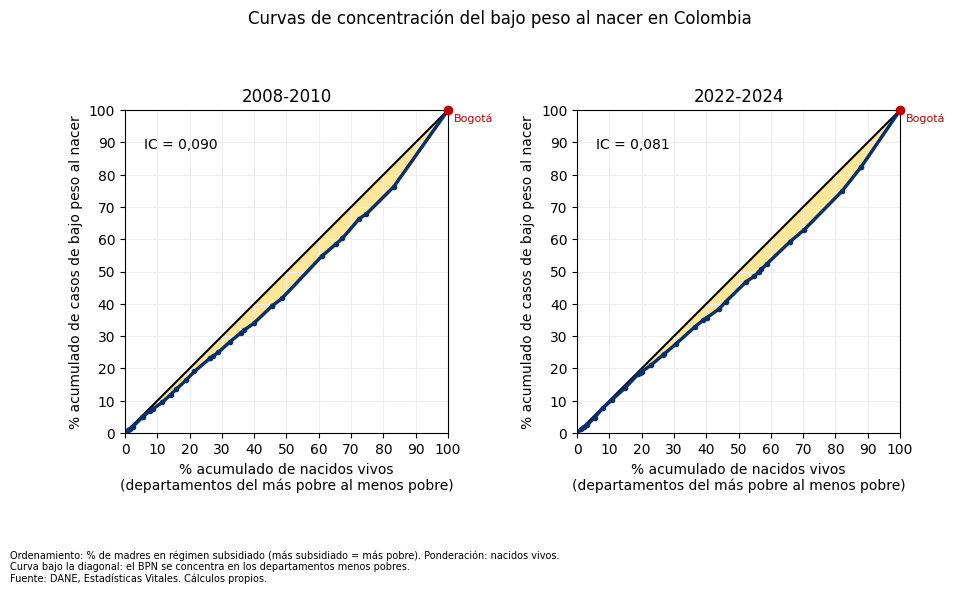

In [19]:
def g3(ax, p):
    ejes(ax, p)
    x, y, cod = puntos(p)
    ax.fill_between(x, x, y, color="#FFE699", lw=0)
    curva(ax, x, y, AZUL)
    i = np.flatnonzero(cod == BOGOTA)
    ax.plot(x[i], y[i], "o", color=ROJO, ms=6, clip_on=False, zorder=5)
    for xi, yi in zip(x[i], y[i]):
        ax.annotate("Bogotá", (xi, yi), xytext=(4, -8), textcoords="offset points", color=ROJO, fontsize=8)
    ax.text(6, 88, f"IC = {coma(IC[p])}")


figura(g3, "Curvas de concentración del bajo peso al nacer en Colombia",
       f"{ORDENAMIENTO}\nCurva bajo la diagonal: el BPN se concentra en los departamentos menos pobres.\n{FUENTE}",
       "G3_curvas_concentracion_trienios.png", ["G3_curva_concentracion_1.png", "G3_curva_concentracion_2.png"])

#### G4. Con Bogotá: los dos trienios superpuestos

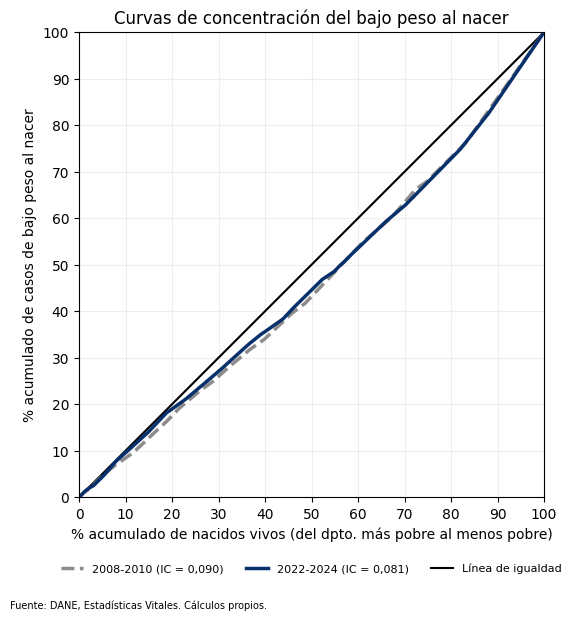

In [20]:
fig, ax = plt.subplots(figsize=(6, 6.5))
ejes(ax, "Curvas de concentración del bajo peso al nacer",
     xlabel="% acumulado de nacidos vivos (del dpto. más pobre al menos pobre)")
p1, p2 = TRIENIOS
curva(ax, *puntos(p1)[:2], "#8C8C8C", marcador=None, ls="--", label=f"{p1} (IC = {coma(IC[p1])})")
curva(ax, *puntos(p2)[:2], AZUL, marcador=None, label=f"{p2} (IC = {coma(IC[p2])})")
h, l = ax.get_legend_handles_labels()
ax.legend(h[1:] + h[:1], l[1:] + l[:1], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False,
          fontsize=8)
fig.text(0.01, -0.02, FUENTE, fontsize=7, va="top")
fig.savefig(RESULTADOS / "G4_curvas_superpuestas.png", dpi=300, bbox_inches="tight")

#### G5. Sin Bogotá

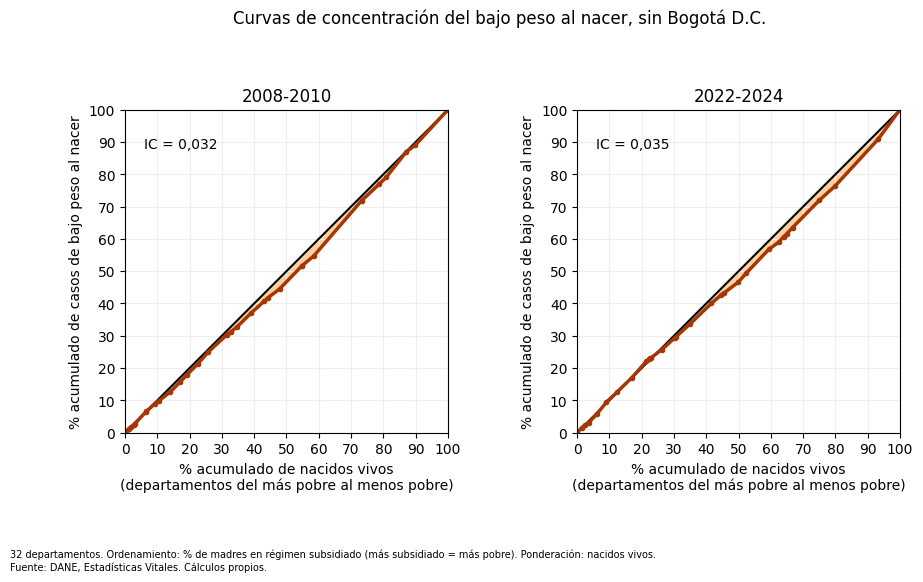

In [21]:
def g5(ax, p):
    ejes(ax, p)
    x, y, _ = puntos(p, sin_bogota=True)
    ax.fill_between(x, x, y, color="#FDD0A2", lw=0)
    curva(ax, x, y, NARANJA)
    ax.text(6, 88, f"IC = {coma(IC_SINBOG[p])}")


figura(g5, "Curvas de concentración del bajo peso al nacer, sin Bogotá D.C.",
       f"32 departamentos. {ORDENAMIENTO}\n{FUENTE}", "G5_curvas_sin_Bogota_trienios.png")

#### G6. Con y sin Bogotá

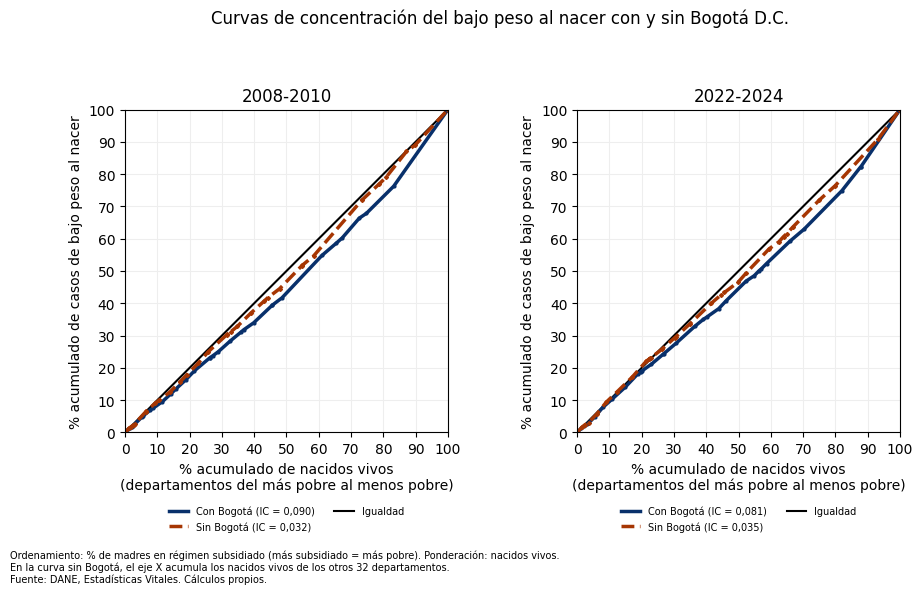

In [22]:
def g6(ax, p):
    ejes(ax, p)
    curva(ax, *puntos(p)[:2], AZUL, ms=2, label=f"Con Bogotá (IC = {coma(IC[p])})")
    curva(ax, *puntos(p, sin_bogota=True)[:2], NARANJA, marcador="D", ms=2, ls="--",
          label=f"Sin Bogotá (IC = {coma(IC_SINBOG[p])})")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[1:] + h[:1], l[1:] + ["Igualdad"], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2,
              frameon=False, fontsize=7)


figura(g6, "Curvas de concentración del bajo peso al nacer con y sin Bogotá D.C.",
       f"{ORDENAMIENTO}\nEn la curva sin Bogotá, el eje X acumula los nacidos vivos de los otros 32 departamentos.\n"
       f"{FUENTE}", "G6_con_sin_Bogota_trienios.png",
       ["G6_con_sin_Bogota_2008_2010.png", "G6_con_sin_Bogota_2022_2024.png"])